In [6]:
import pandas as pd

df = pd.read_csv('/content/crop_recommendation_synthetic_500.csv')

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nCrop distribution:")
print(df["label"].value_counts())

Dataset shape: (500, 8)

Column names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

First 5 rows:


,N,P,K,temperature,humidity,ph,rainfall,label
0,104,11,65,28.84,92.75,6.61,32.74,muskmelon
1,54,54,75,18.06,11.90,7.21,46.85,chickpea
2,95,20,40,27.11,91.49,6.46,18.99,muskmelon
3,17,34,41,27.02,74.99,6.67,38.48,mungbean
4,27,67,23,28.05,43.61,7.08,87.94,pigeonpeas



Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0

Crop distribution:
label
muskmelon      25
chickpea       25
mungbean       25
pigeonpeas     25
apple          25
coconut        25
rice           25
blackgram      25
orange         25
kidneybeans    25
coffee         25
maize          25
grapes         25
mango          25
lentil         25
watermelon     25
papaya         25
mothbeans      25
banana         25
pomegranate    25
Name: count, dtype: int64


In [7]:

# Check data types and dataset information
print("DATASET INFORMATION")
df.info()

print("\nSTATISTICAL SUMMARY")
display(df.describe().round(2))

print("\nDATA TYPES")
print(df.dtypes)


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            500 non-null    int64  
 1   P            500 non-null    int64  
 2   K            500 non-null    int64  
 3   temperature  500 non-null    float64
 4   humidity     500 non-null    float64
 5   ph           500 non-null    float64
 6   rainfall     500 non-null    float64
 7   label        500 non-null    object 
dtypes: float64(4), int64(3), object(1)
memory usage: 31.4+ KB

STATISTICAL SUMMARY


,N,P,K,temperature,humidity,ph,rainfall
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,45.82,50.63,50.41,25.69,70.17,6.38,94.87
std,33.79,34.95,52.03,4.07,23.31,0.63,47.97
min,0.00,0.00,0.00,14.80,10.00,4.44,15.76
25%,19.00,22.00,22.00,22.75,55.65,5.93,57.68
50%,32.00,49.00,35.00,25.72,75.28,6.38,91.82
75%,78.00,67.00,53.00,28.77,89.94,6.84,117.19
max,133.00,145.00,205.00,35.41,100.00,8.23,251.93



DATA TYPES
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object


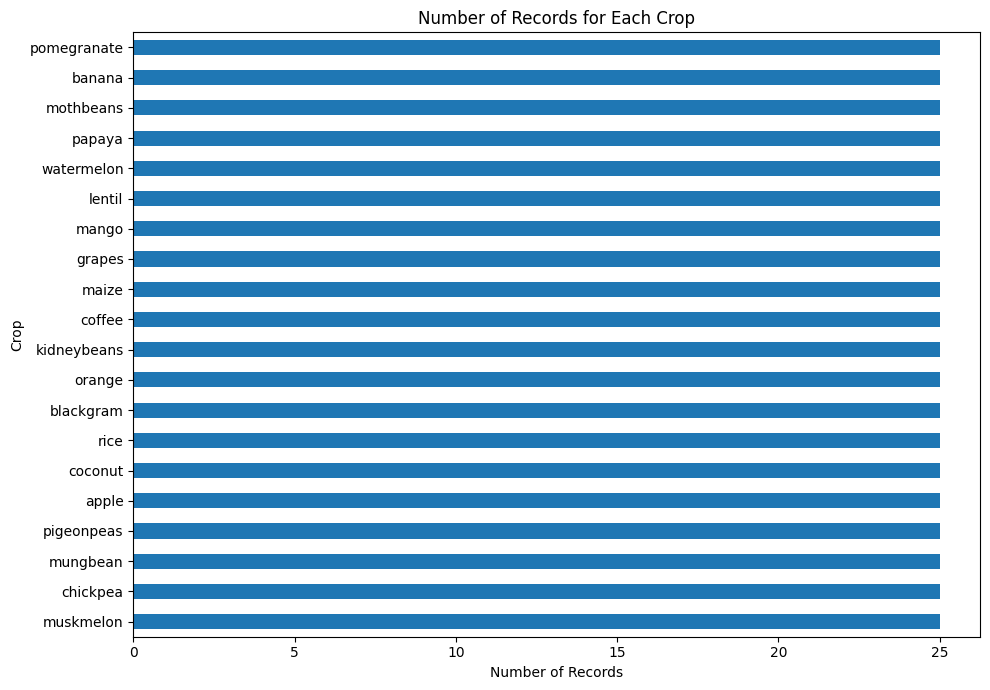

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count the records for each crop
crop_counts = df["label"].value_counts().sort_values()

plt.figure(figsize=(10, 7))
crop_counts.plot(kind="barh")

plt.title("Number of Records for Each Crop")
plt.xlabel("Number of Records")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()


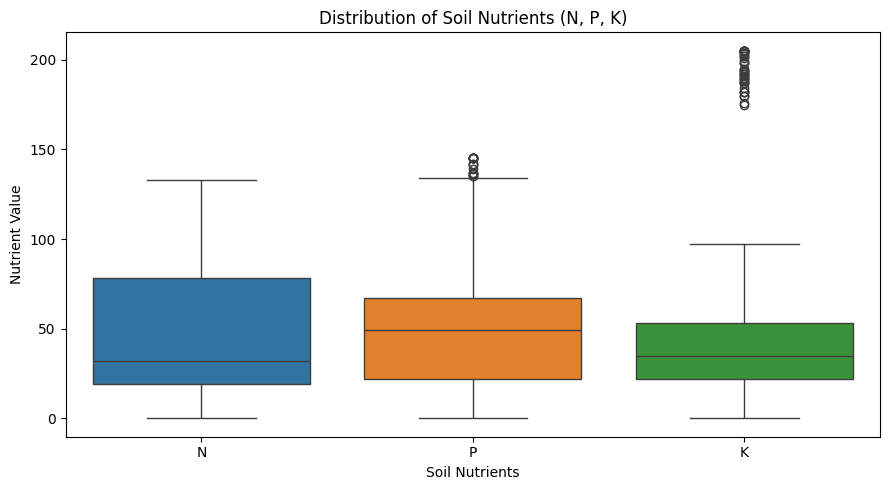

In [9]:

plt.figure(figsize=(9, 5))

sns.boxplot(data=df[["N", "P", "K"]])

plt.title("Distribution of Soil Nutrients (N, P, K)")
plt.xlabel("Soil Nutrients")
plt.ylabel("Nutrient Value")
plt.tight_layout()
plt.show()


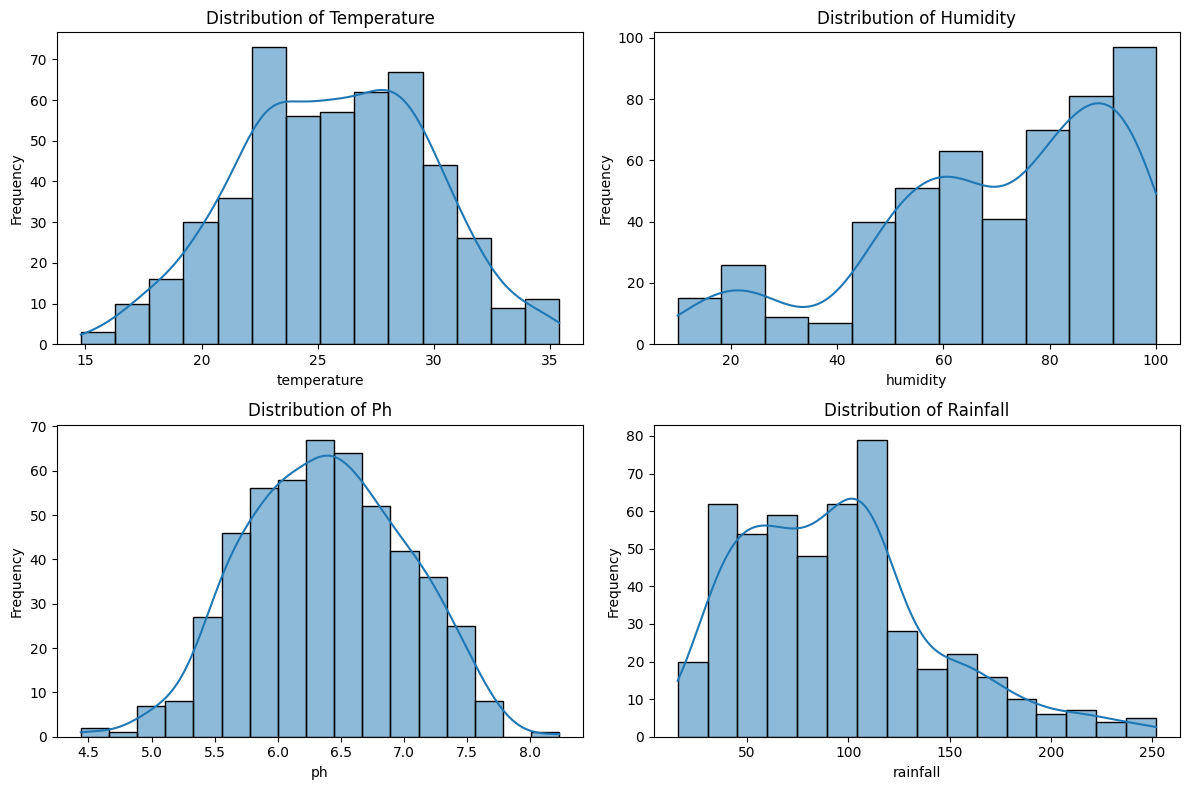

In [10]:

weather_soil = ["temperature", "humidity", "ph", "rainfall"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for column, ax in zip(weather_soil, axes.flatten()):
    sns.histplot(data=df, x=column, kde=True, ax=ax)
    ax.set_title(f"Distribution of {column.capitalize()}")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


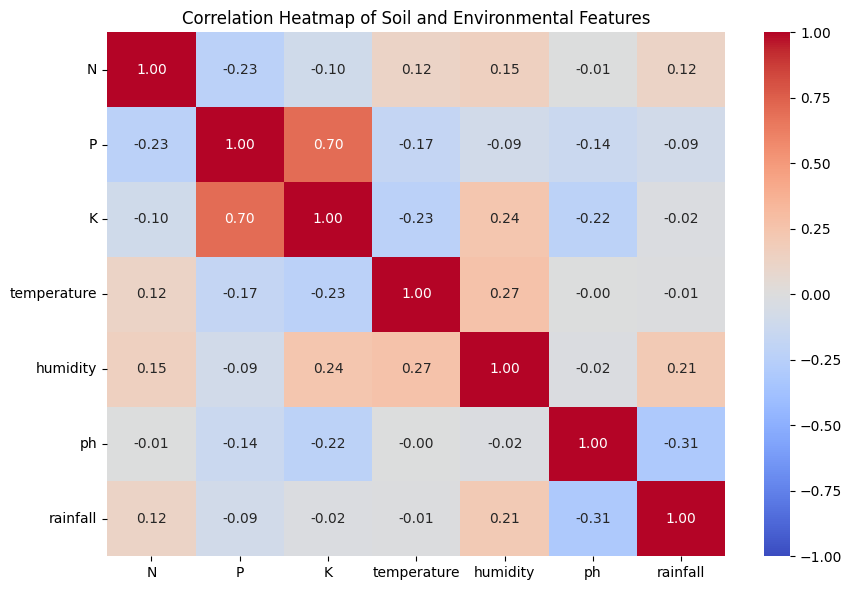

In [11]:

# Correlation between numerical features
numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Soil and Environmental Features")
plt.tight_layout()
plt.show()


In [12]:

# Identify potential outliers using the IQR method

numeric_df = df.select_dtypes(include="number")

Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outlier_counts = (
    (numeric_df < lower_limit) |
    (numeric_df > upper_limit)
).sum()

print("Potential outliers in each numerical column:")
print(outlier_counts)


Potential outliers in each numerical column:
N               0
P              18
K              50
temperature     0
humidity        0
ph              3
rainfall       16
dtype: int64
